In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

In [19]:
df=pd.read_excel('/content/Online Retail.xlsx')

In [20]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [21]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df = df.drop_duplicates().copy()

df["CustomerID"] = pd.to_numeric(df["CustomerID"], errors="coerce")
df = df.dropna(subset=["CustomerID", "InvoiceNo", "InvoiceDate"])

df = df[
    ~df["InvoiceNo"].astype(str).str.startswith("C")
    & (df["Quantity"] > 0)
    & (df["UnitPrice"] > 0)
].copy()

df["CustomerID"] = df["CustomerID"].astype(int)
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

print("Cleaned dataset:", df.shape)

Cleaned dataset: (392692, 9)


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


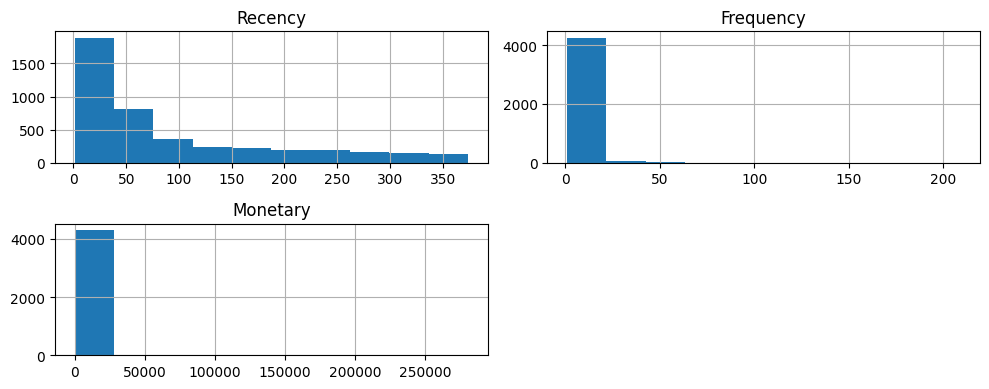

In [22]:
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate",
             lambda x: (reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum")
).reset_index()

display(rfm.head())

rfm[["Recency", "Frequency", "Monetary"]].hist(figsize=(10, 4))
plt.tight_layout()
plt.show()

In [23]:
X = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

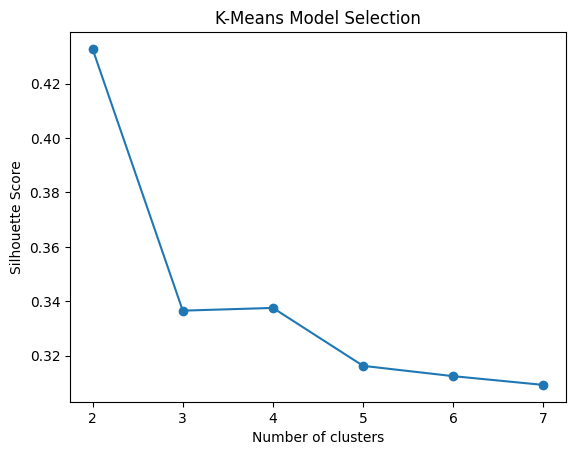

Best K: 2
Silhouette Score: 0.433


In [24]:
scores = []

for k in range(2, 8):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    scores.append(silhouette_score(X_scaled, labels))

plt.plot(range(2, 8), scores, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Silhouette Score")
plt.title("K-Means Model Selection")
plt.show()

best_k = np.argmax(scores) + 2

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
rfm["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("Best K:", best_k)
print("Silhouette Score:", round(max(scores), 3))

In [25]:
dbscan = DBSCAN(eps=0.7, min_samples=10)
rfm["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

print(rfm["DBSCAN_Cluster"].value_counts().sort_index())

DBSCAN_Cluster
-1      39
 0    4299
Name: count, dtype: int64


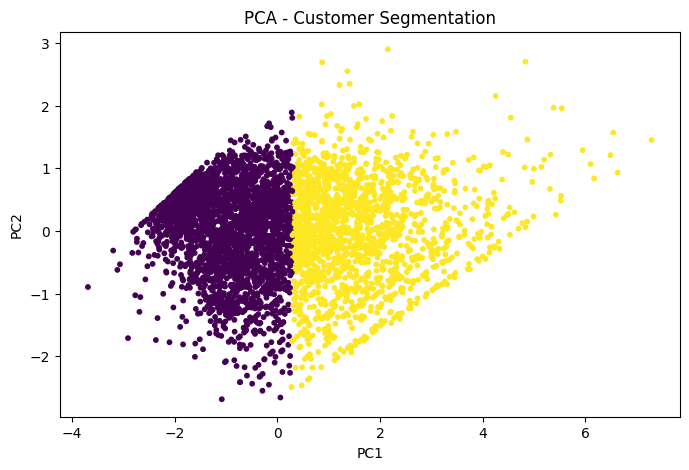

Variance explained: 93.87 %


In [26]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1],
            c=rfm["KMeans_Cluster"], cmap="viridis", s=10)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA - Customer Segmentation")
plt.show()

print("Variance explained:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

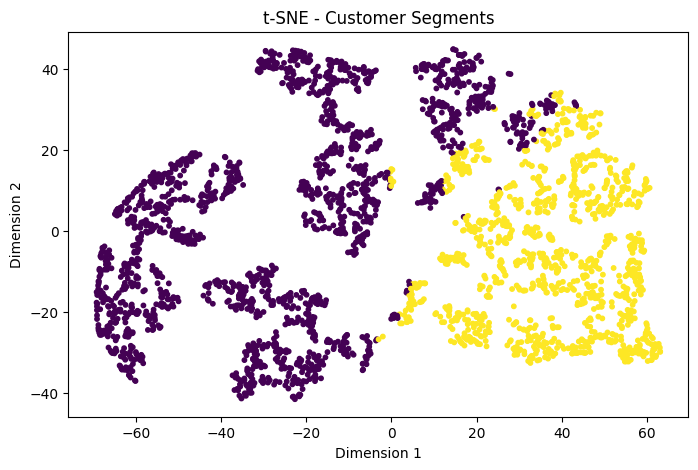

In [27]:
n = min(3000, len(X_scaled))
idx = np.random.RandomState(42).choice(len(X_scaled), n, replace=False)

X_tsne = TSNE(
    n_components=2,
    perplexity=min(30, n - 1),
    random_state=42,
    init="pca",
    learning_rate="auto"
).fit_transform(X_scaled[idx])

plt.figure(figsize=(8, 5))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1],
            c=rfm["KMeans_Cluster"].iloc[idx], cmap="viridis", s=10)
plt.title("t-SNE - Customer Segments")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.show()

In [28]:
summary = rfm.groupby("KMeans_Cluster").agg(
    Customers=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).round(2)

def persona(row):
    if (row["Avg_Recency"] <= rfm["Recency"].median()
        and row["Avg_Frequency"] >= rfm["Frequency"].median()
        and row["Avg_Monetary"] >= rfm["Monetary"].median()):
        return "Champions - VIP rewards"
    elif row["Avg_Recency"] > rfm["Recency"].median():
        return "At Risk - Win-back offers"
    elif row["Avg_Frequency"] >= rfm["Frequency"].median():
        return "Loyal - Bundle offers"
    else:
        return "Potential - Repeat purchase offers"

summary["Marketing_Persona"] = summary.apply(persona, axis=1)

display(summary)

rfm.to_csv("customer_segments.csv", index=False)
summary.to_csv("marketing_personas.csv")

print("Case study completed!")

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Marketing_Persona
KMeans_Cluster,,,,,,
0,2672,134.09,1.67,495.59,1324229.69,At Risk - Win-back offers
1,1666,25.89,8.44,4539.60,7562979.20,Champions - VIP rewards


Case study completed!


In [29]:
print("Cluster sizes:")
print(rfm["KMeans_Cluster"].value_counts())

print("\nAverage RFM by cluster:")
display(
    rfm.groupby("KMeans_Cluster")[
        ["Recency", "Frequency", "Monetary"]
    ].mean().round(2)
)

print("\nK-Means silhouette score:")
print(round(silhouette_score(X_scaled, rfm["KMeans_Cluster"]), 3))

Cluster sizes:
KMeans_Cluster
0    2672
1    1666
Name: count, dtype: int64

Average RFM by cluster:


,Recency,Frequency,Monetary
KMeans_Cluster,,,
0,134.09,1.67,495.59
1,25.89,8.44,4539.60



K-Means silhouette score:
0.433
